# Notebook métricas de evaluación con RR Lyrae

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

En esta actividad trabajaremos con un problema de clasificación binaria: distinguir estrellas **RR Lyrae** de otras estrellas a partir de sus colores fotométricos.

### Los objetivos son
- entrenar un clasificador simple
- evaluar su rendimiento con distintas métricas
- interpretar una matriz de confusión
- comparar accuracy con precision, recall y F1
- discutir qué métrica conviene según el objetivo científico

### Contexto
Las RR Lyrae son estrellas variables pulsantes muy importantes en astronomía. En un catálogo grande, un clasificador puede ayudarnos a encontrar candidatas RR Lyrae, pero no basta con mirar solo el accuracy.


### Descripción de los datos
El set de datos que usará para esta tarea es sobre estrellas. Las características son colores en distintos filtros del [sistema ugriz de SDSS](https://www.physics.unlv.edu/~jeffery/astro/photometry/photometry_sdss.html), que son un indicador si la estrella emite luz más azul, verde, amarilla o roja. Queremos predecir a partir de estas características si la estrella es un tipo especial de estrella llamada variable RR Lyrae.

- Las características son los colores u-g, g-r, r-i, i-z
- El target es 0 (no RRLyrae) y 1 (RRLyrae)


In [18]:
import pandas as pd
import numpy as np

import sklearn.tree
from sklearn.tree import DecisionTreeClassifier #modelo
from sklearn.tree import plot_tree #visualizacion arbol
from sklearn.model_selection import train_test_split
from sklearn import metrics #métricas
from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate #validación cruzada
from sklearn.model_selection import KFold, StratifiedKFold #validación cruzada

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay #matriz de confusión


from scipy import stats

In [19]:
from io import StringIO
from IPython.display import Image
import pydotplus
from sklearn.tree import export_graphviz

In [20]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

font = {'size': 8}

matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=8)
matplotlib.rc('ytick', labelsize=8)
matplotlib.rcParams['figure.dpi'] = 300

pd.set_option('display.max_columns', 100) #Para poder visualizar todas las columnas del dataframe
pd.set_option('display.max_colwidth', 100)

## Primer paso: exploración de los datos

Siempre es importante hacer una análisis exploratorio del conjunto de datos que trabajaremos. Leemos el archivo como un dataframe y extraemos información básica

In [21]:
#from google.colab import drive
#drive.mount('/content/drive')

In [22]:
#cargamos los datos como arreglos numpy
ruta = "/home/gaspar/Escritorio/Universidad/Machine_Learning/Notebooks/"
features= np.loadtxt(ruta + "RRLyrae_features_small.txt", delimiter=',')
targets= np.loadtxt(ruta + "RRLyrae_labels_small.txt", delimiter=',')

In [23]:
columnas = ["u-g", "g-r", "r-i", "i-z"]
df = pd.DataFrame(features, columns=columnas)
df["RR_Lyrae"] = targets.astype(int)

df.head()

,u-g,g-r,r-i,i-z,RR_Lyrae
0,0.311,0.714,0.093,0.204,0
1,0.332,0.965,0.122,0.032,0
2,0.394,1.019,0.147,0.096,0
3,0.285,0.865,0.120,0.039,0
4,0.386,0.977,0.181,0.080,0


In [24]:
contador_pulsar = 0
contador_nopulsar = 0
for i in df["RR_Lyrae"]:
    if i == 0:
        contador_nopulsar += 1
    else:
        contador_pulsar += 1

print("Cantidad de estrellas RR Lyrae:", contador_pulsar)
print("Cantidad de estrellas noramles:", contador_nopulsar)
print("Total de estrellas:", len(df["RR_Lyrae"]))

Cantidad de estrellas RR Lyrae: 483
Cantidad de estrellas noramles: 2000
Total de estrellas: 2483


### Preguntas
1. ¿Este es un problema de clasificación o regresión?
2. ¿Es un problema binario o multiclase?
3. ¿Qué representa la variable objetivo?
4. ¿Las clases están balanceadas o desbalanceadas?
5. ¿Por qué esto podría ser importante al elegir una métrica de evaluación?

- Este es un problema de clasificacion, ya que el objetivo es determinar su una estrella es una RR Lyrae o no.
- El problema es binario, dado que solo hay dos opciones mutuamente excluyentes posibles para clasificar a la estrella.
- Representa un estado de pertenencia de la estrella, donde el valor numerico actua como un indicador logico para confirmar o descartar el que la estrella sea una RR Lyrae.
- De una muestra de 2483 estrellas, existen 483 que son RR Lyrae (19.5%), por lo que las clases estan desbalanceadas.
- El accuracy se vuelve una métrica engañosa e inútil. Por ejemplo, un modelo que diga "No hay estrellas RR Lyrae" va a tener un accuracy elevado sin haber detectado ni una sola estrella de este tipo.

#### Haga una visualización de sólo dos columnas para revisar los colores de las RR Lyrae y las no RRLyrae

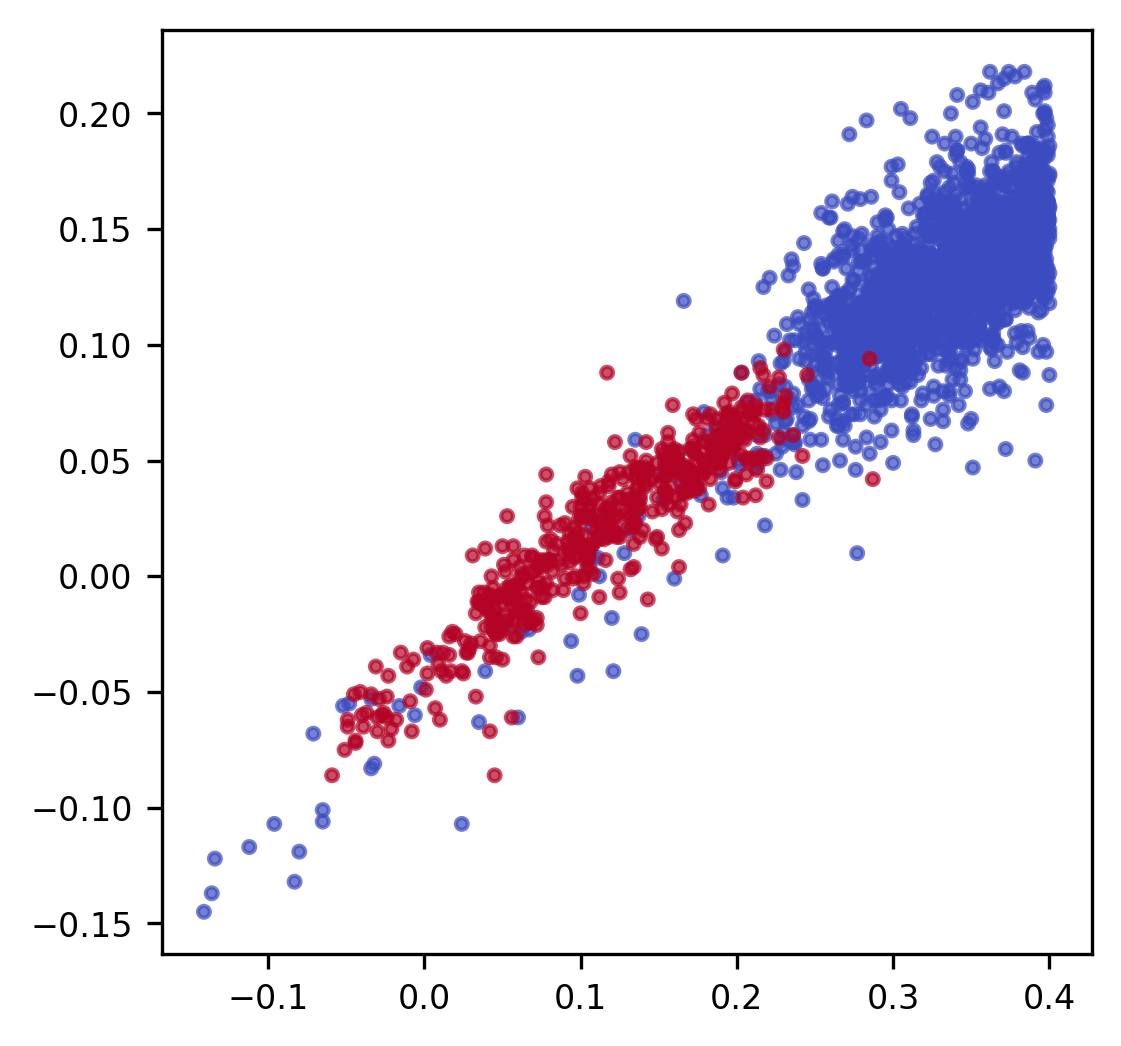

In [25]:
#complete la celda
plt.figure(figsize=(4,4))

sc=plt.scatter(df['u-g'], df['r-i'], c=df['RR_Lyrae'], cmap='coolwarm', s=8, alpha=0.7)
plt.show()

### Pregunta
1. ¿Se observan regiones donde las clases parecen separarse?
2. A simple vista, ¿esperarías que un árbol de decisión funcione razonablemente bien?

- Se observa un patron bien definido a lo largo del eje x. Ambas clases en el grafico se pueden separar en tres regiones, aproximadamente en x = -0.13 y x = 0.22.
- Si, se esperaria que funcione bien. Dado que la separacion planteada anteriormente es vertical, un arbol de desiciones podria ser capaz de realizar cortes en estos valores del eje x.

#### Separe los datos en entrenamiento y prueba

In [26]:
X = df[["u-g", "g-r", "r-i", "i-z"]]
y = df["RR_Lyrae"]

In [27]:
#complete la celda
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.3, random_state=42)

In [28]:
X_train.shape

(1738, 4)

### Antes de continuar

Las clases en este problema no están perfectamente balanceadas.

Piense en la forma en que podríamos separar los datos en entrenamiento y prueba, y responda:

1. ¿Qué problema podría ocurrir si hacemos la partición de manera completamente aleatoria, sin preocuparnos por la proporción de clases?
2. ¿Por qué eso podría afectar la evaluación del modelo?
3. ¿Qué tipo de precaución cree que sería razonable tomar al construir los conjuntos de entrenamiento y prueba en este caso?

- Al hacer una division aleatoria corremos el riesgo de que las RR Lyrae queden desproporcionadamente mal repartidas. En un caso extremo el conjunto de prueba podria recibir muy pocos o casi ningun pulsar, haciendo que la muestra no sea representativa de la poblacion original.
- Afecta directamente la validez de las metricas. Si el conjunto de prueba termina con una cantidad insignificante de estrellas tipo RR Lyrae no se puede evaluar de forma confiable la verdadera capacidad del modelo para detectar esta clase de interes.
- Lo ideal seria asegurarse de mantener el mismo porcentaje de estrellas RR Lyrae y estrellas "no RR Lyrae" en ambos grupos. Asi garantizamos que tanto el conjunto de entrenamiento como el de prueba sean un "espejo" fiel de la proporcion real de los datos.

#### Ahora entrenaremos un árbol de decisión (modelo base)

In [29]:
model_tree = DecisionTreeClassifier(random_state=42)
model_tree.fit(X_train, y_train)
#entrene el modelo y genere las predicciones
y_pred=model_tree.predict(X_test)


#### Visualicemos el árbol

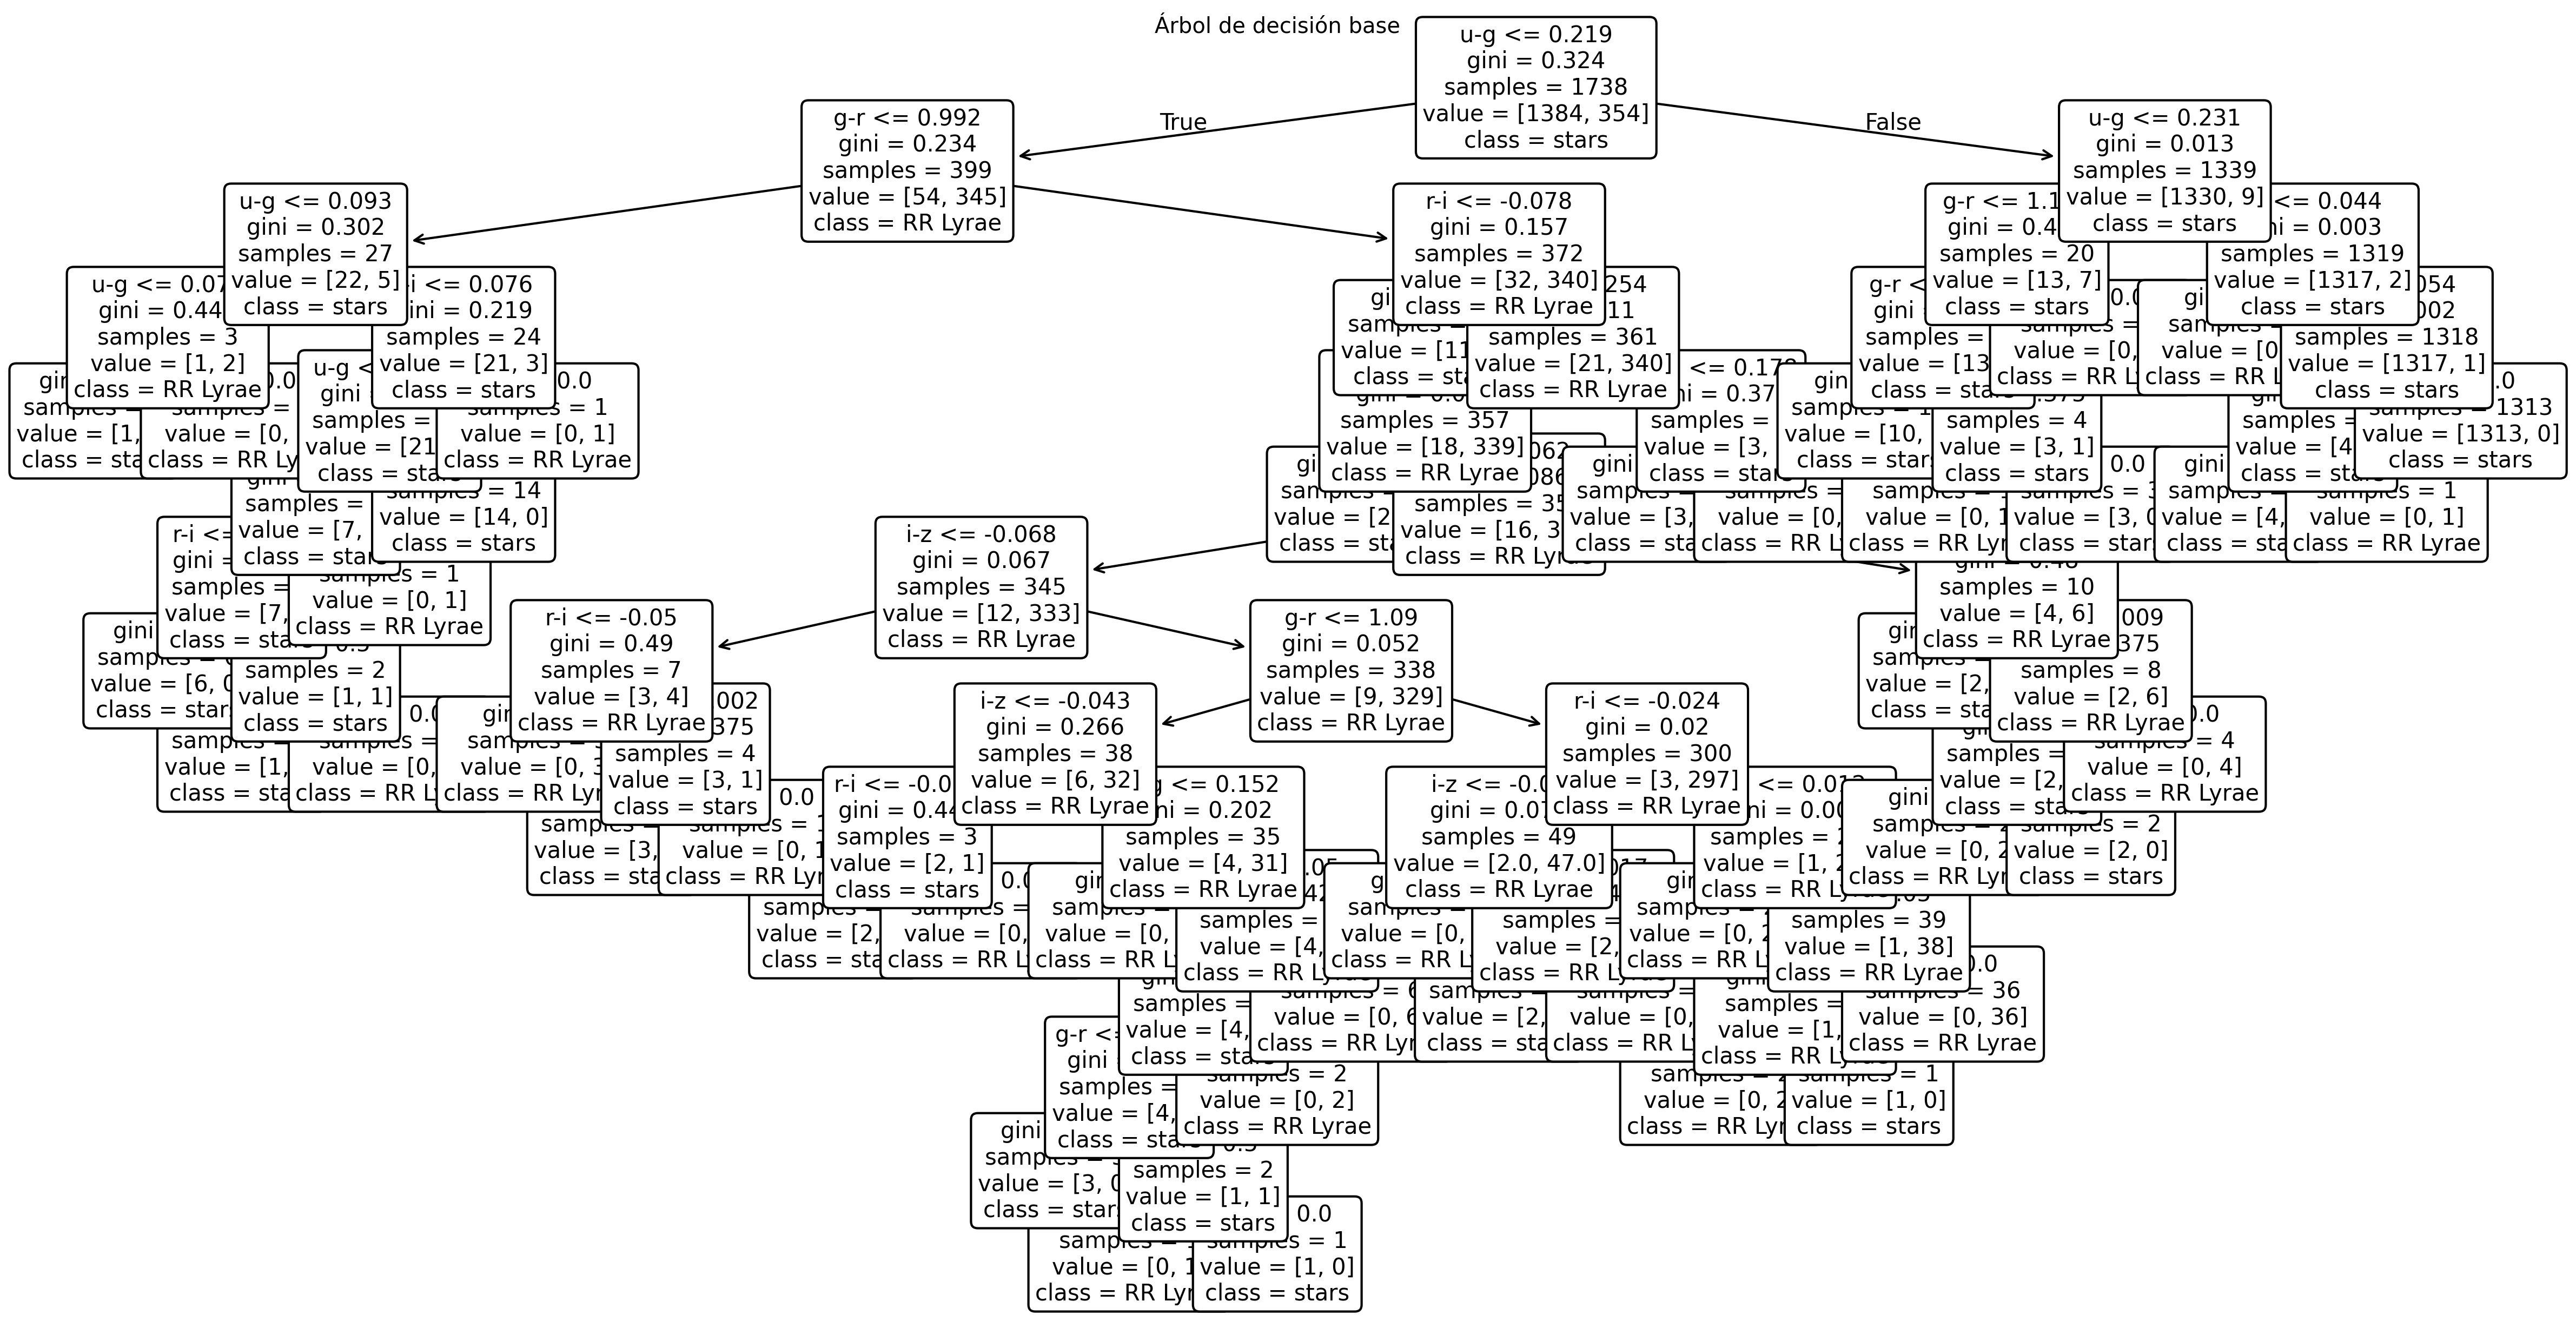

In [30]:
plt.figure(figsize=(20,10))

plot_tree(
    model_tree,
    feature_names=X.columns,
    class_names=["stars", "RR Lyrae"],
    filled=False,
    rounded=True,
    #max_depth=3,
    fontsize=10
)

plt.title("Árbol de decisión base")
plt.show()

In [31]:
# Recordatorio: Las características siempre se permutan aleatoriamente en cada división.
# Por lo tanto, la mejor división encontrada puede variar, incluso con los mismos datos
# de entrenamiento y max_features=n_features, si la mejora del criterio es idéntica
# para varias divisiones enumeradas durante la búsqueda de la mejor división.
# Para obtener un comportamiento determinista durante el ajuste, random_state debe estar fijo.

dot_data = StringIO()

export_graphviz(
    model_tree,
    out_file=dot_data,
    feature_names=['u-g', 'g-r', 'r-i', 'i-z'],
    class_names=['stars', 'RR Lyrae'],
    filled=True,
    rounded=True,
    special_characters=True
)

graph = pydotplus.graph_from_dot_data(dot_data.getvalue().replace("\n", ""))
nodes = graph.get_node_list()

for node in nodes:
    if node.get_label() and 'value = [' in node.get_label():

        values = [float(ii) for ii in node.get_label().split('value = [')[1].split(']')[0].split(',')]
        values = [int(255 * v / sum(values)) for v in values]

        if values[0] > values[1]:
            alpha = int(values[0] - values[1])
            alpha = '{:02x}'.format(alpha)
            color = '#9ecae1' + str(alpha)   # turquesa
        else:
            alpha = int(values[1] - values[0])
            alpha = '{:02x}'.format(alpha)
            color = '#756bb1' + str(alpha)   # magenta

        node.set_fillcolor(color)

Image(graph.create_png())

InvocationException: GraphViz's executables not found

### Preguntas

Observe la estructura del árbol y responda brevemente:

1. ¿El árbol parece muy simple o bastante complejo? Justifique a partir del número de niveles o divisiones.
2. ¿Qué desventaja podría tener un árbol demasiado grande en un problema como este?

1. El arbol es excesivamente complejo, dado que presenta mas de 10 niveles de profundidad y muchas mas ramificaciones muy detalladas, las cuales buscan aislar nodos terminales con 1 o 2 muestras (samples = 1).

2. Un arbol asi de profundo demuestra un claro overfitting, es decir, el modelo esta memorizando el ruido del conjunto de entrenamiento en lugar de aprender patrones generales. Esto va a provocar que al predecir nuevos datos de prueba el modelo cometa errores y tenga un muy mal rendimiento en su capacidad de generalizacion.

#### Miremos las métricas accuracy para set de entrenamiento y prueba

In [32]:
print(metrics.accuracy_score(y_train, model_tree.predict(X_train))) #train score

print(metrics.accuracy_score(y_test, model_tree.predict(X_test))) #test score

1.0
0.9651006711409396


#### Otras métricas

In [33]:
print("Precision:", metrics.precision_score(y_test, y_pred))
print("Recall   :", metrics.recall_score(y_test, y_pred))
print("F1-score :", metrics.f1_score(y_test, y_pred))

Precision: 0.8759124087591241
Recall   : 0.9302325581395349
F1-score : 0.9022556390977443


In [34]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[599,  17],
       [  9, 120]])

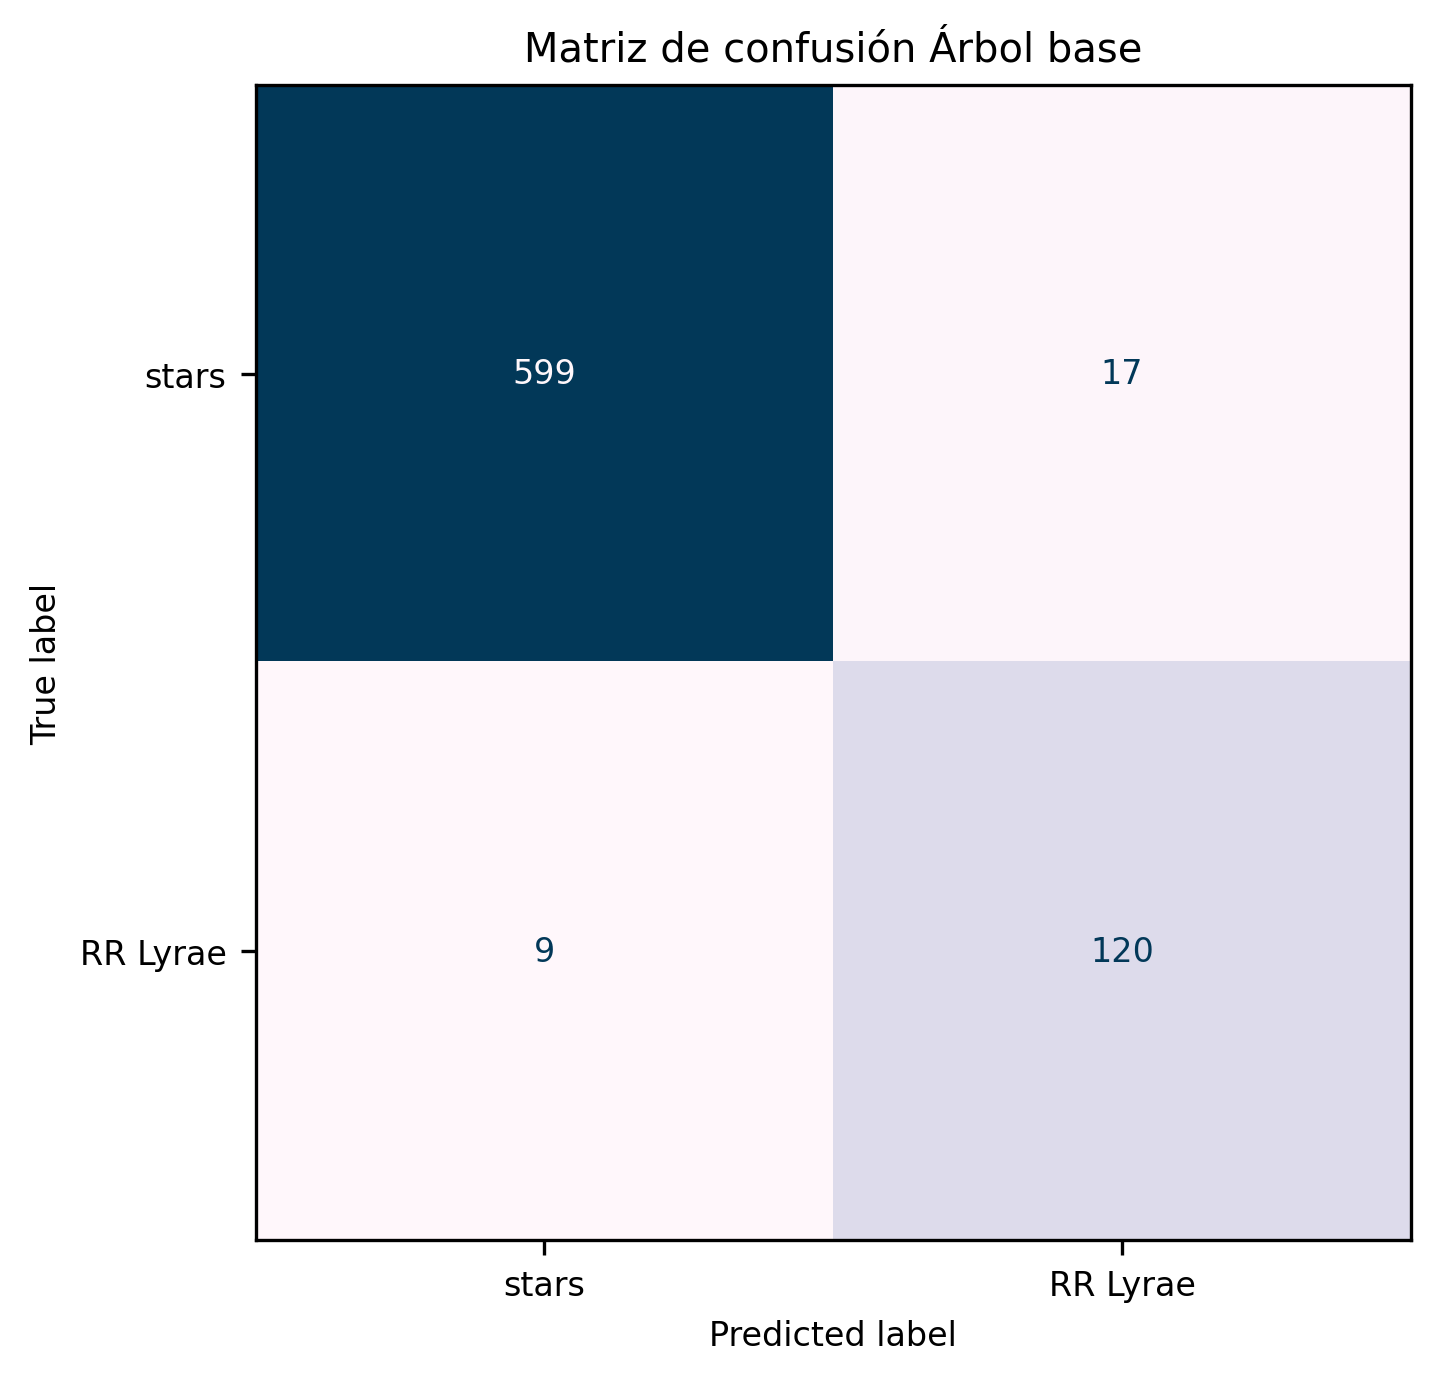

In [35]:
fig, ax = plt.subplots(figsize=(5,5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["stars", "RR Lyrae"])
disp.plot(cmap="PuBu", ax=ax, colorbar=False)

plt.title("Matriz de confusión Árbol base")
plt.show()

#### A partir de la matriz de confusión obtenida:
1.  Identifique los valores de:
   - verdaderos positivos (TP)
   - verdaderos negativos (TN)
   - falsos positivos (FP)
   - falsos negativos (FN)
2. Calcule las métricas "a mano"



TP: 120 ; TN: 599 ; FP: 17 ; FN: 9

In [36]:
# Metricas "a mano"

TP = 120 
TN = 599
FP = 17 
FN = 9

Precision = TP / (TP + FP)
print(f"Precision: {Precision:.3}")

Accuracy = (TP + TN) / (TP + TN + FP + FN)
print(f"Accuracy: {Accuracy:.3}")

Recall = TP / (TP + FN)
print(f"Recall: {Recall:.3}")

F1 = (2 * Precision * Recall) / (Precision + Recall)
print(f"F1: {F1:.3}")

Precision: 0.876
Accuracy: 0.965
Recall: 0.93
F1: 0.902


### Preguntas
1. Explique con sus palabras qué significa, en este problema:
   - un falso positivo
   - un falso negativo

2. Si el objetivo científico fuera encontrar la mayor cantidad posible de RR Lyrae, ¿qué tipo de error preocuparía más?

3. Si el objetivo fuera construir una muestra final más limpia, ¿qué tipo de error preocuparía más?

1. Un falso positivo es una estrella que fue erroneamente clasificada como RR Lyrae, cuando en la realidad de los datos era una estrella normal (no RR Lyrae). Por otro lado, un falso negativo es una estrella erroneamente clasificada como normal, cuando en realidad era efectivamente una tipo RR Lyrae.

2. El error mas preocupante seria aquel que aumente la cantidad de falsos negativos, es decir, el error que minimiza la deteccion de este tipo de estrellas. Esto se traduce en buscar maximizar el Recall.

3. En este caso el error mas preocupante es aquel que aumente los falsos positivos, para ello se debe buscar maximizar la Precision, considerando adicionalmente que estos son mayores en cantidad que los falsos negativos (17 FP v/s 9 FN).

#### Todo parece funcionar bien, pero sólo hicimos un split. Necesitamos que el resultados sea robusto. Para esto, implementaremos Cross-validation usando [k-fold](https://scikit--learn-org.translate.goog/stable/modules/generated/sklearn.model_selection.KFold.html?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=tc)

In [37]:
# Esta es la versión estándar. Importante: no baraja los datos, por lo que si tus
# ejemplos positivos están todos al principio o al final, podría llevar a resultados
# desastrosos.

cv1 = KFold(n_splits = 5)

#Esta es la versión 2: se ha añadido el barajado (¡recomendado!)

cv2 = KFold(shuffle = True, n_splits = 5, random_state=5)

# LA ESTRATIFICACIÓN asegura que las distribuciones de clases en cada división se
# asemejen a las del conjunto de datos completo.

cv3 = StratifiedKFold(shuffle = True, n_splits = 5, random_state=5)


### Efecto de la estratificación: veamos el conteo de clases en cada conjunto de divisiones.

In [38]:
cv1.split(X, y)

<generator object _BaseKFold.split at 0x7ab90a369000>

In [39]:
for train, test in cv1.split(X, y):
    print('train -  {}   |   test -  {}'.format(np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1503  483]   |   test -  [497]
train -  [1503  483]   |   test -  [497]
train -  [1503  483]   |   test -  [497]
train -  [1504  483]   |   test -  [496]
train -  [1987]   |   test -  [ 13 483]


In [40]:
for train, test in cv2.split(X, y):
    print('train -  {}   |   test -  {}'.format(np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1600  386]   |   test -  [400  97]
train -  [1610  376]   |   test -  [390 107]
train -  [1587  399]   |   test -  [413  84]
train -  [1599  388]   |   test -  [401  95]
train -  [1604  383]   |   test -  [396 100]


In [41]:
for train, test in cv3.split(X, y):
    print('train -  {}   |   test -  {}'.format(np.bincount(y.loc[train]), np.bincount(y.loc[test])))

train -  [1600  386]   |   test -  [400  97]
train -  [1600  386]   |   test -  [400  97]
train -  [1600  386]   |   test -  [400  97]
train -  [1600  387]   |   test -  [400  96]
train -  [1600  387]   |   test -  [400  96]


### La función [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html#sklearn.model_selection.cross_validate) proporciona los puntajes (especificados por el parámetro de evaluación elegido), en forma de diccionario.

In [42]:
scores1 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv1, scoring = 'accuracy')

scores2 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv2, scoring = 'accuracy')

scores3 = cross_validate(DecisionTreeClassifier(), X, y, cv = cv3, scoring = 'accuracy')

In [43]:
scores3

{'fit_time': array([0.00749779, 0.00659013, 0.00864029, 0.00865507, 0.00829625]),
 'score_time': array([0.00449252, 0.00548863, 0.00404954, 0.00344419, 0.00432658]),
 'test_score': array([0.9778672 , 0.9637827 , 0.96579477, 0.97580645, 0.95362903])}

Solo nos interesa el 'test_score'

#### Calculamos el promedio y $\sigma$

In [44]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['test_score'].std()))

0.784 0.379


In [45]:
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['test_score'].std()))

0.965 0.011


In [46]:
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['test_score'].std()))

0.967 0.009


La validación cruzada sin barajar (`cv1`) produce un resultado muy inestable, con una desviación estándar extremadamente alta. Esto ocurre porque los datos están ordenados por clase, de modo que algunos folds no representan bien el problema completo.

Al activar el barajado (`cv2`), el rendimiento mejora drásticamente y la dispersión disminuye. Sin embargo, el método que resulta más apropiado para este problema es `StratifiedKFold` (`cv3`), ya que además de mezclar los datos, conserva aproximadamente la proporción de clases en cada fold.

En problemas de clasificación desbalanceada, esta última estrategia suele ser la más recomendable.

In [47]:
scores1 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv1, scoring = 'recall')

scores2 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv2, scoring = 'recall')

scores3 = cross_validate(DecisionTreeClassifier(random_state=1), X,y, cv = cv3, scoring = 'recall')

/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [48]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['test_score'].std()))
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['test_score'].std()))
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['test_score'].std()))

nan nan
0.903 0.016
0.925 0.019


### ¿Por qué aparece este warning?

En algunos folds generados por `KFold` sin barajado, el conjunto de prueba contiene solo ejemplos de una clase. En ese caso, el recall de la clase positiva (RR Lyrae) no puede calcularse, porque no hay positivos reales en ese fold.

Esto muestra que una estrategia de partición inadecuada puede hacer que la evaluación sea inestable, engañosa o incluso inválida.

#### También extraeremos los train scores, que nos servirán cuando estemos diagnosticando el modelo a través de bias vs variance.¶

In [49]:
scores1 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv1, scoring = 'recall', \
                         return_train_score = True)

scores2 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv2, scoring = 'recall', \
                         return_train_score = True)

scores3 = cross_validate(DecisionTreeClassifier(), X,y, cv = cv3, scoring = 'recall',
                         return_train_score = True)

/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", 

In [50]:
print("{:.3f}".format(scores1['test_score'].mean()), "{:.3f}".format(scores1['train_score'].mean()))
print("{:.3f}".format(scores2['test_score'].mean()), "{:.3f}".format(scores2['train_score'].mean()))
print("{:.3f}".format(scores3['test_score'].mean()), "{:.3f}".format(scores3['train_score'].mean()))

nan nan
0.913 1.000
0.927 1.000


### La función  `cross_validate` es útil para calcular el puntaje, pero no produce etiquetas predichas.

#### Estas pueden obtenerse utilizando la función [`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html), que guarda las predicciones para cada uno de los k-folds de prueba y las compila juntas.


In [51]:
model1 = DecisionTreeClassifier(random_state = 3)

y_cv3 = cross_val_predict(model1, X,y, cv = cv3)
# Estas son las predicciones,
# y son independientes del parámetro de evaluación

In [52]:
metrics.confusion_matrix(targets,y_cv3)

array([[1955,   45],
       [  33,  450]])

### Sin embargo, las cosas pueden cambiar si uso un esquema de validación cruzada diferente:

In [53]:
model2 = DecisionTreeClassifier(random_state = 3)

y_cv2 = cross_val_predict(model2, X,y, cv = cv2)

In [54]:
np.sum(y_cv3-y_cv2)

np.int64(10)

In [55]:
np.sum(y_cv2)

np.int64(485)

In [56]:
np.sum(y_cv3 != y_cv2) #comparando las predicciones

np.int64(52)

In [57]:
metrics.confusion_matrix(targets,y_cv2)

array([[1955,   45],
       [  43,  440]])

In [58]:
metrics.confusion_matrix(targets,y_cv3)

array([[1955,   45],
       [  33,  450]])

In [59]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, title, X, y, ylim=None, cv=5,
                        n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5), scoring = 'accuracy'):
    """
    Generate a simple plot of the test and training learning curve.

    Parameters
    ----------
    estimator : object type that implements the "fit" and "predict" methods
        An object of that type which is cloned for each validation.

    title : string
        Title for the chart.

    X : array-like, shape (n_samples, n_features)
        Training vector, where n_samples is the number of samples and
        n_features is the number of features.

    y : array-like, shape (n_samples) or (n_samples, n_features), optional
        Target relative to X for classification or regression;
        None for unsupervised learning.

    ylim : tuple, shape (ymin, ymax), optional
        Defines minimum and maximum yvalues plotted.

    cv : int, cross-validation generator or an iterable, optional
        Determines the cross-validation splitting strategy.
        Possible inputs for cv are:
          - None, to use the default 3-fold cross-validation,
          - integer, to specify the number of folds.
          - :term:`CV splitter`,
          - An iterable yielding (train, test) splits as arrays of indices.

        For integer/None inputs, if ``y`` is binary or multiclass,
        :class:`StratifiedKFold` used. If the estimator is not a classifier
        or if ``y`` is neither binary nor multiclass, :class:`KFold` is used.

        Refer :ref:`User Guide <cross_validation>` for the various
        cross-validators that can be used here.

    n_jobs : int or None, optional (default=None)
        Number of jobs to run in parallel.
        ``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.
        ``-1`` means using all processors. See :term:`Glossary <n_jobs>`
        for more details.

    train_sizes : array-like, shape (n_ticks,), dtype float or int
        Relative or absolute numbers of training examples that will be used to
        generate the learning curve. If the dtype is float, it is regarded as a
        fraction of the maximum size of the training set (that is determined
        by the selected validation method), i.e. it has to be within (0, 1].
        Otherwise it is interpreted as absolute sizes of the training sets.
        Note that for classification the number of samples usually have to
        be big enough to contain at least one sample from each class.
        (default: np.linspace(0.1, 1.0, 5))
    """
    plt.figure(figsize=(10,6))
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel(str(scoring))

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring = scoring, shuffle=True, random_state=42)
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Test score from cross-validation")

    plt.legend(loc="best")
    return plt

In [60]:
model = DecisionTreeClassifier(random_state = 5)

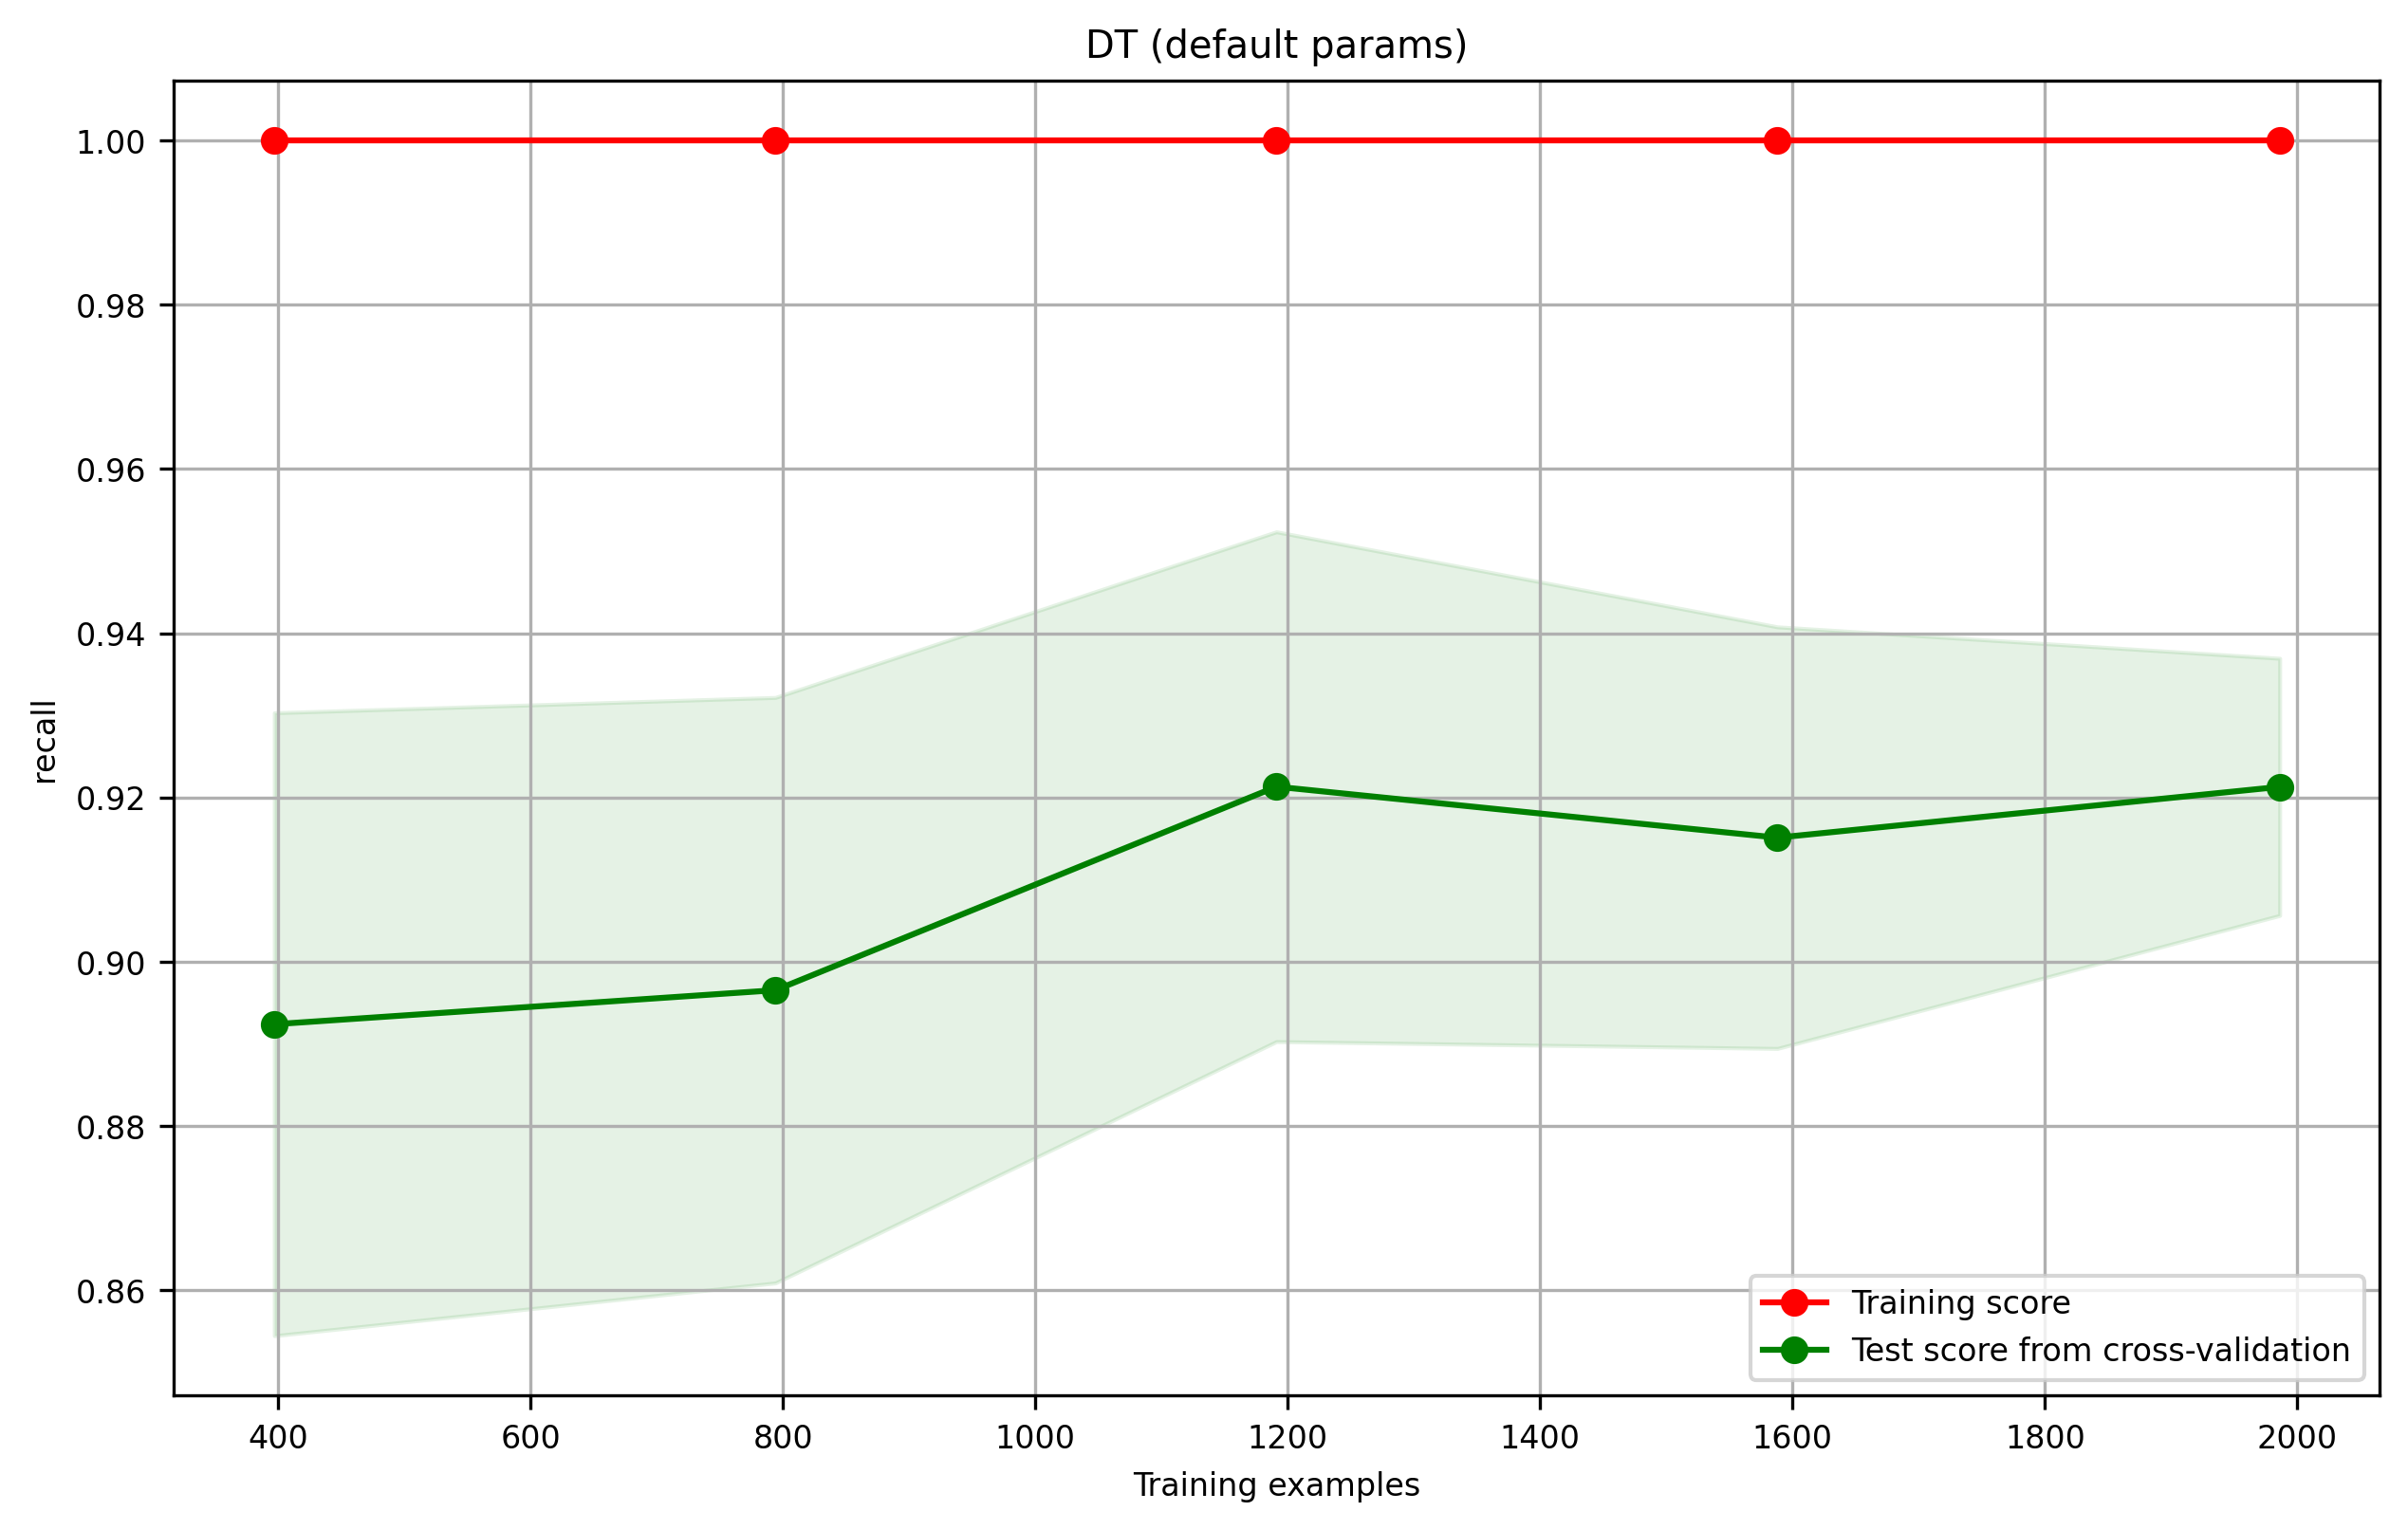

In [61]:
plot_learning_curve(model, 'DT (default params)', X, y,  cv = cv3, scoring = 'recall');

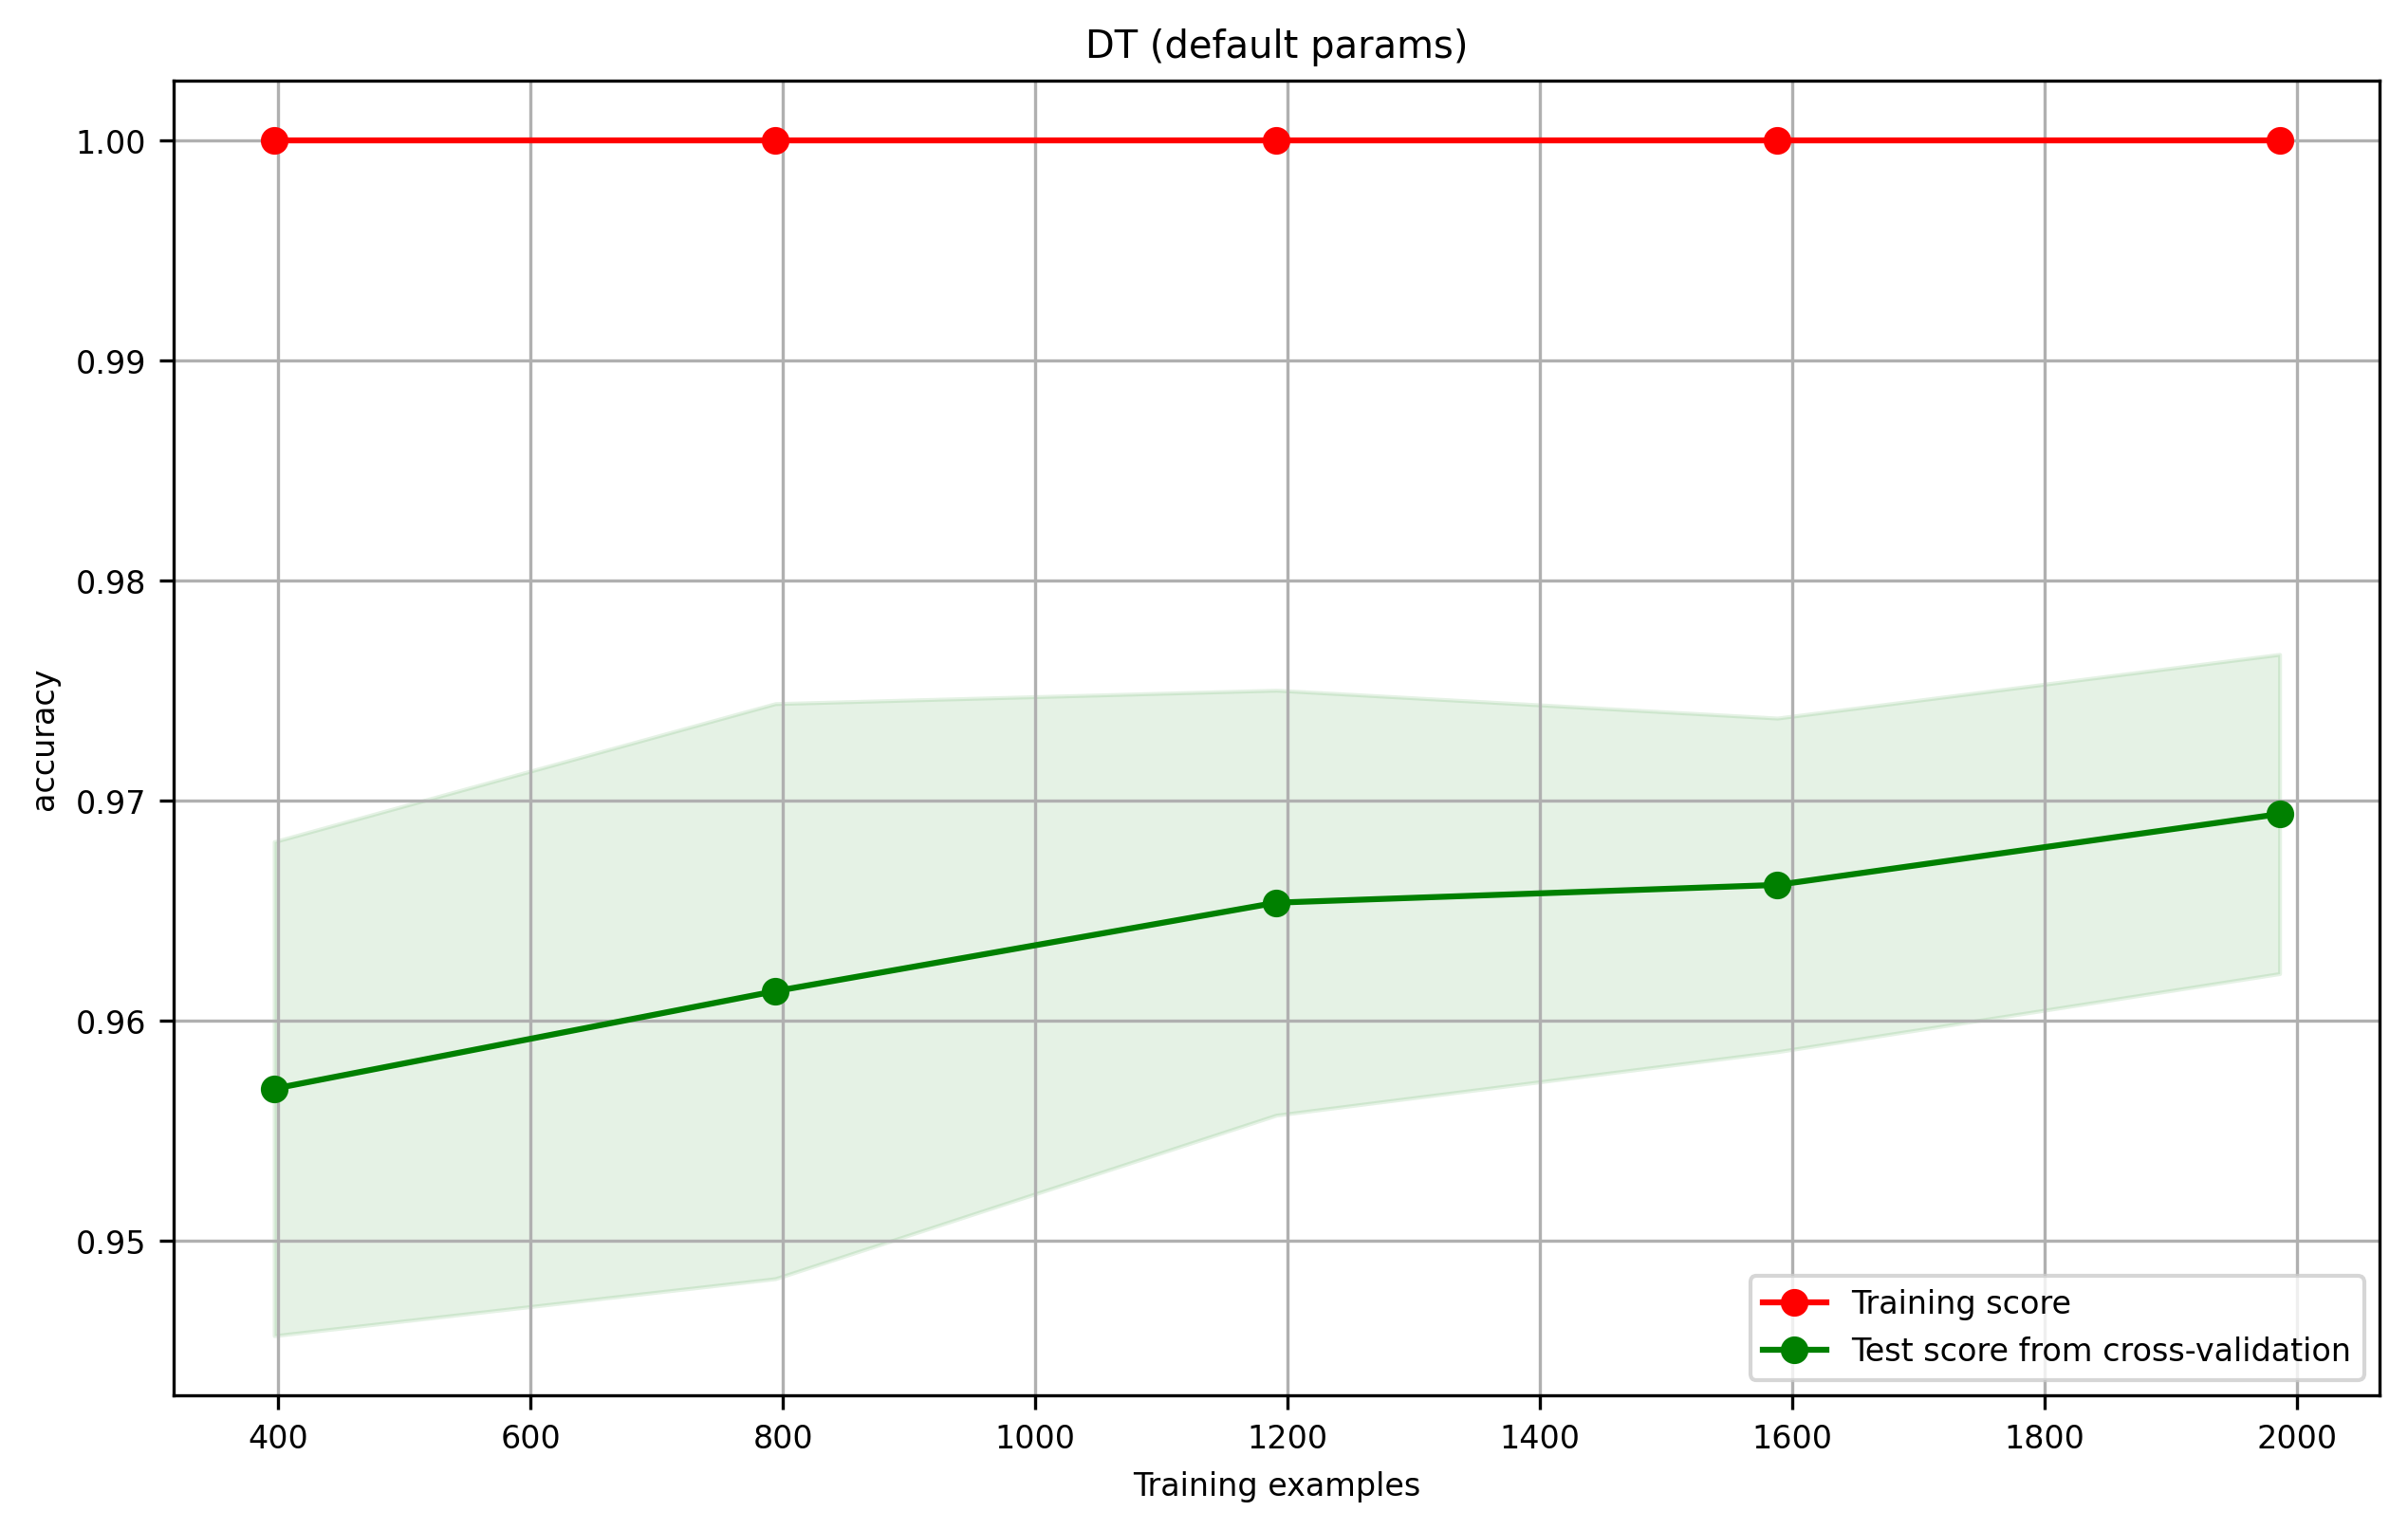

In [62]:
plot_learning_curve(model, 'DT (default params)', X, y,  cv = cv3, scoring = 'accuracy');

### **Preguntas**

Responda brevemente:

1. ¿Existe una brecha entre la curva de entrenamiento y la de validación? ¿Qué sugiere eso?
2. ¿El rendimiento de validación mejora al agregar más ejemplos?
3. ¿Hablaría aquí de alto sesgo, alta varianza o sobreajuste moderado? Justifique.
4. Escriba una conclusión general sobre el comportamiento del árbol base a partir de estas curvas.

1. Existe una notable y presistente brecha entre las curvas, lo cual demuestra que este modelo presenta overfitting, es decir, se memoriza el conjunto de entrenamiento en lugar de aprender patrones generales.

2. El rendimiento mejora progresivamente a medida que aumentan los datos. Sin embargo, el margen de mejora es cada vez menor y la brecha con el entrenamiento no se cierra por completo, indicando que agregar mas datos de por si no resolvera el problema de overfitting.

3. Hablaria de alta varianza. Esto se justifica en que el error en entrenamiento es cero (un score perfecto de 1.0), pero existe una discrepancia significativa con el conjunto de validacion. El arbol por defecto se ha vuelto demasiado complejo.

4. El arbol de decision logra buenas metricas en validación (0.92 recall y 0.97 accuracy aproximadamente), pero memoriza completamente los datos de entrenamiento. Al presentar alta varianza el modelo no generalizara de forma optima ante nuevos datos no vistos. Para solucionarlo es necesario aplicar tecnicas de "poda" (ejemplo: limitar max_depth), es decir, modificar los hiperparametros del arbol de desiciones para reducir su complejidad y cerrar la brecha entre entrenamiento y validacion.

### Desafío: ¿un árbol más simple generaliza mejor?

Entrene ahora un segundo árbol, más restringido que el árbol base. Por ejemplo, puede probar con:

- `max_depth=3`, o
- `min_samples_leaf=10`

Luego compare su rendimiento con el árbol base usando:

- accuracy
- precision
- recall
- F1-score



In [63]:
cv3 = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)

metricas = ['accuracy', 'precision', 'recall', 'f1']

# 1. Arbol Base (sin restricciones)
modelo_base = DecisionTreeClassifier(random_state=5)
scores_base = cross_validate(modelo_base, X, y, cv=cv3, scoring=metricas)

# 2. Arbol restringido por Profundidad Maxima (max_depth=3)
modelo_depth3 = DecisionTreeClassifier(max_depth=3, random_state=5)
scores_depth3 = cross_validate(modelo_depth3, X, y, cv=cv3, scoring=metricas)

# Arbol restringido por Minimo de Muestras en Hoja (min_samples_leaf=10)
modelo_leaf10 = DecisionTreeClassifier(min_samples_leaf=10, random_state=5)
scores_leaf10 = cross_validate(modelo_leaf10, X, y, cv=cv3, scoring=metricas)

# Consolidación de resultados promedio
df_comparacion = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Árbol Base (Sin límites)': [
        scores_base['test_accuracy'].mean(),
        scores_base['test_precision'].mean(),
        scores_base['test_recall'].mean(),
        scores_base['test_f1'].mean()
    ],
    'Árbol Restringido (max_depth=3)': [
        scores_depth3['test_accuracy'].mean(),
        scores_depth3['test_precision'].mean(),
        scores_depth3['test_recall'].mean(),
        scores_depth3['test_f1'].mean()
    ],
    'Árbol Restringido (min_samples_leaf=10)': [
        scores_leaf10['test_accuracy'].mean(),
        scores_leaf10['test_precision'].mean(),
        scores_leaf10['test_recall'].mean(),
        scores_leaf10['test_f1'].mean()
    ]
})

print(df_comparacion)

     Métrica  Árbol Base (Sin límites)  Árbol Restringido (max_depth=3)  \
0   Accuracy                  0.969391                         0.977043   
1  Precision                  0.922046                         0.924699   
2     Recall                  0.921284                         0.960631   
3   F1-Score                  0.921459                         0.942126   

   Árbol Restringido (min_samples_leaf=10)  
0                                 0.973016  
1                                 0.923245  
2                                 0.939927  
3                                 0.931168  


<module 'matplotlib.pyplot' from '/home/gaspar/Escritorio/entorno_virtual_3119/lib/python3.11/site-packages/matplotlib/pyplot.py'>

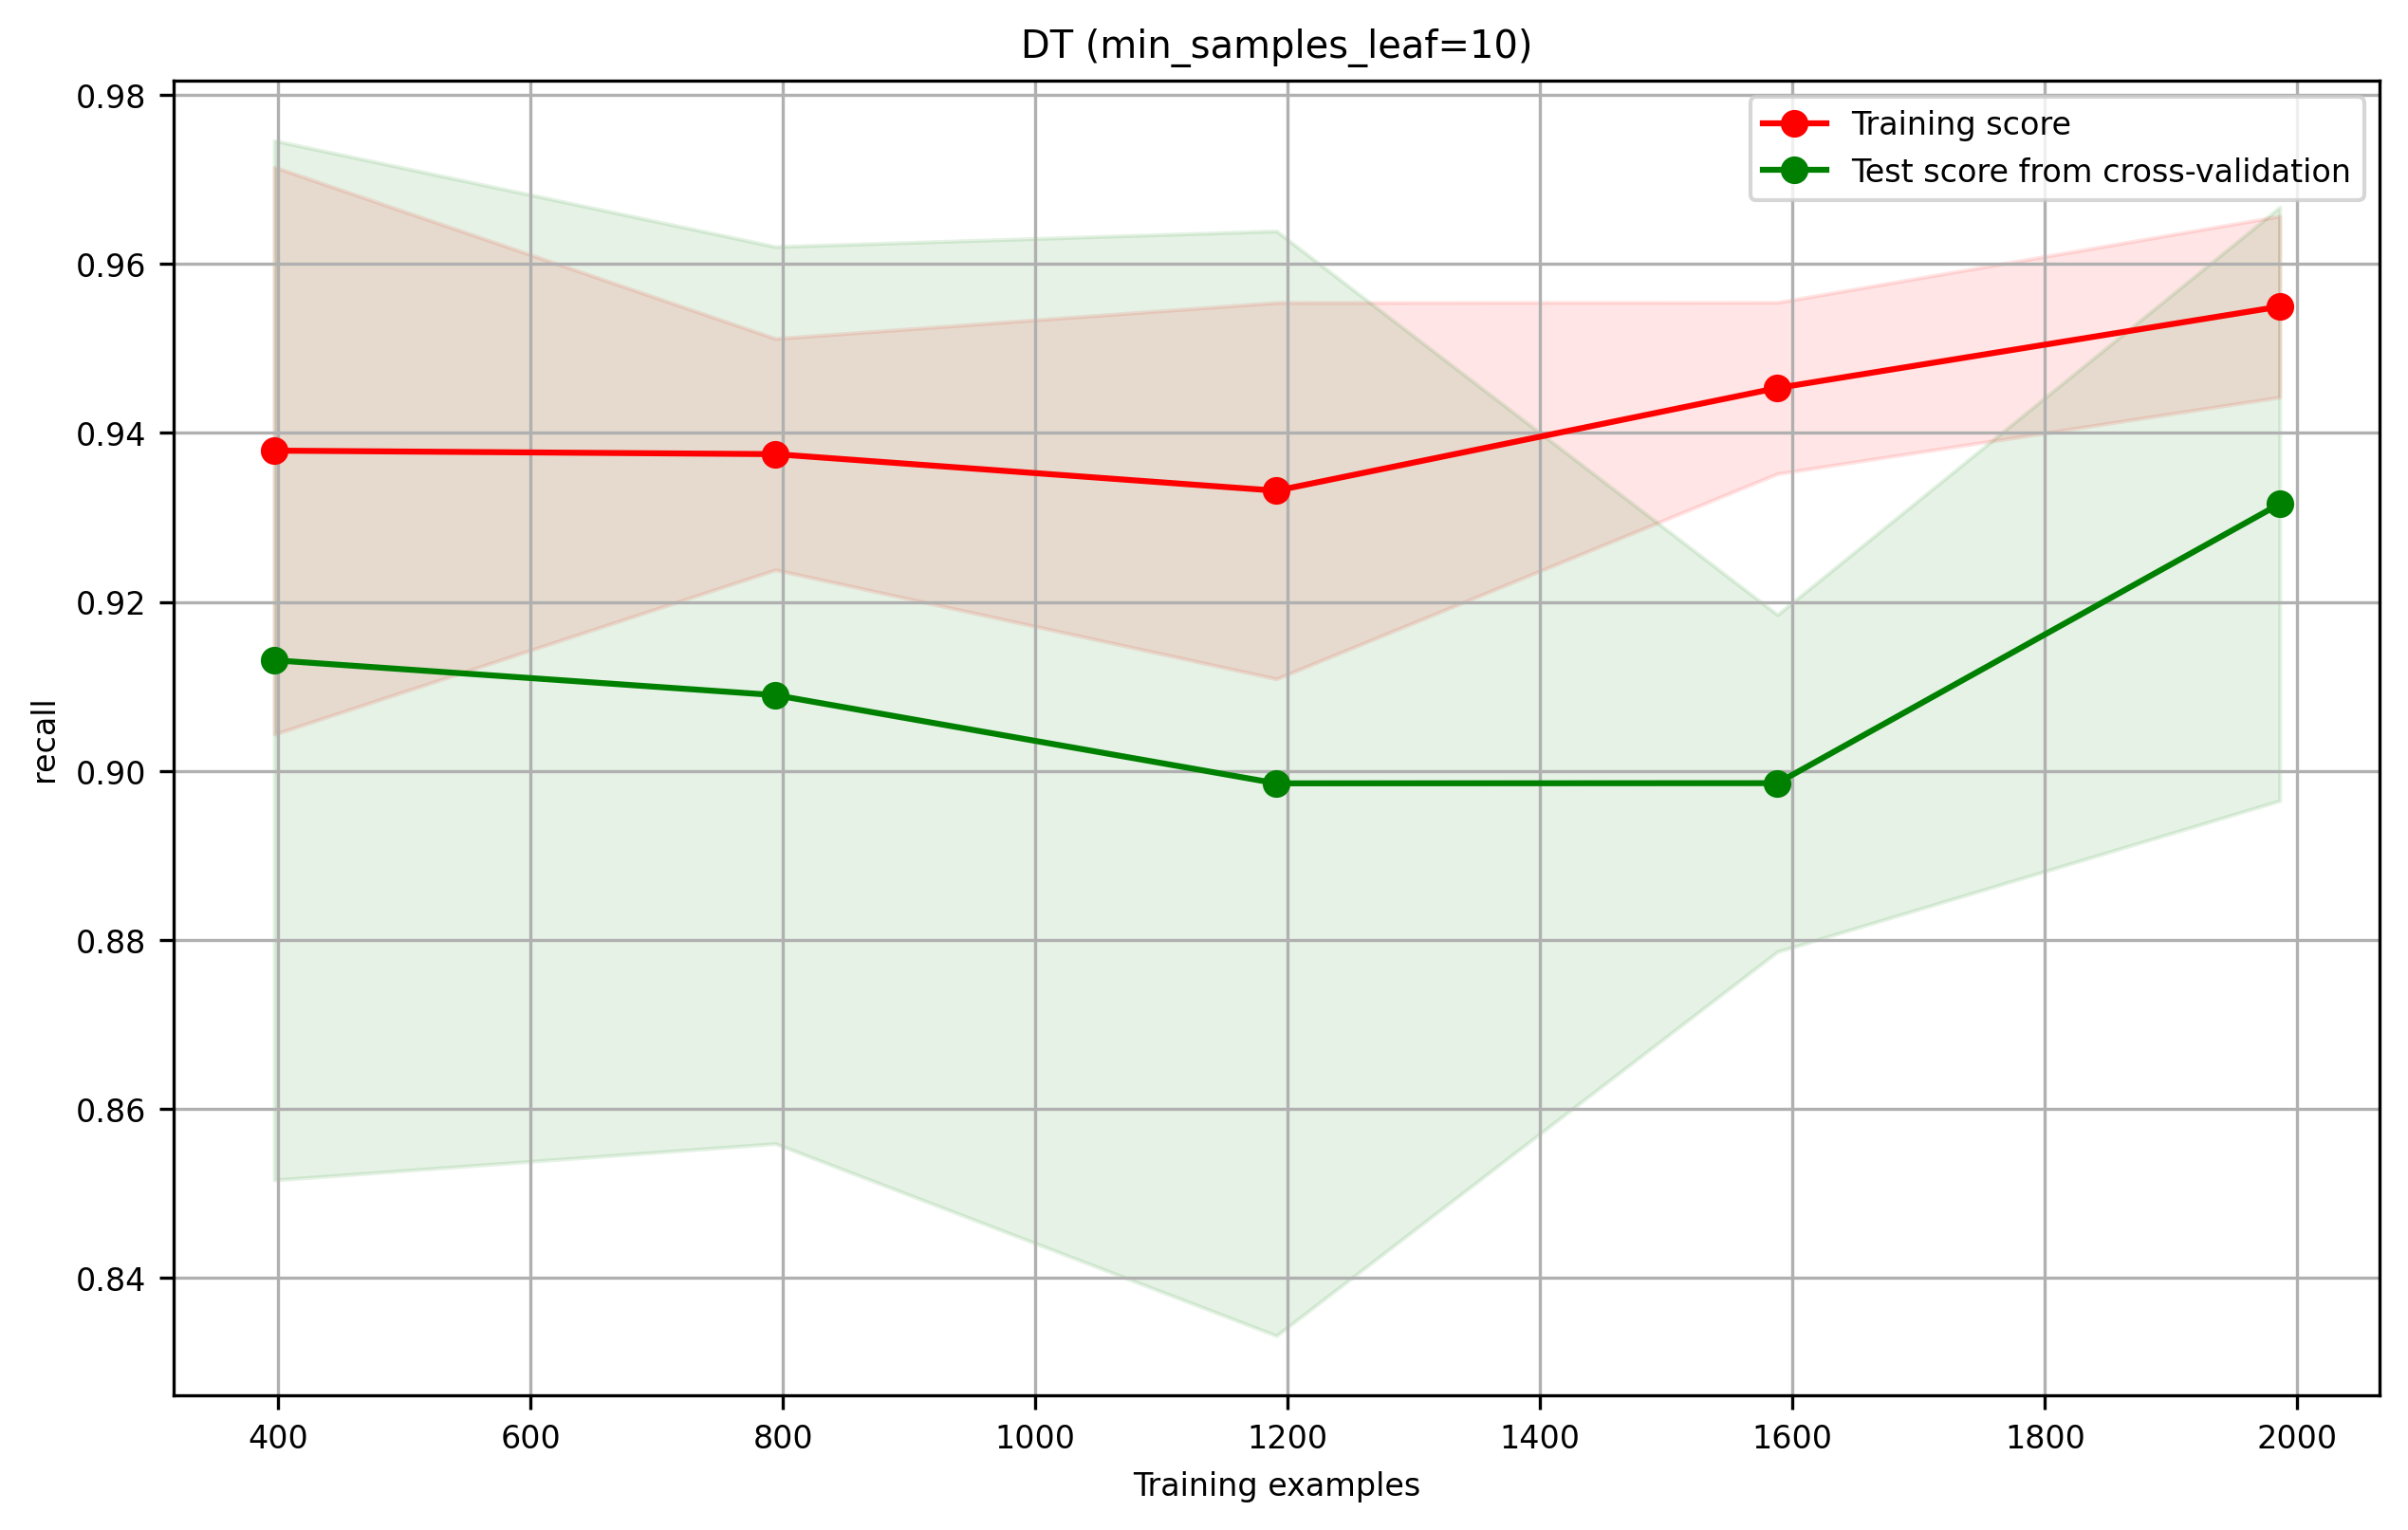

In [64]:
plot_learning_curve(modelo_leaf10, 'DT (min_samples_leaf=10)', X, y, cv=cv3, scoring='recall')

### Preguntas

A partir de los resultados obtenidos con validación cruzada:

1. ¿Qué ocurrió con el rendimiento al restringir la complejidad del árbol?
2. ¿El árbol más simple empeoró o mejoró la generalización?
3. ¿Qué sugieren estos resultados sobre el árbol base?
4. En este problema, ¿parece conveniente usar el árbol sin restricciones?
5. ¿Qué métrica le parece más importante para decidir entre ambos modelos?

1. El rendimiento mejoro en todas las metricas. Al limitar la profundidad con max_depth=3 o el numero minimo de hojas con min_samples_leaf=10 se eliminaron las divisiones innecesarias que presentaba el arbol antiguo, permitiendole enfocarse en los patrones verdaderos en lugar de aprenderse el ruido de memoria.

2. Mejoro mucho la generalizacion, lo cual se confirma de dos formas: 
- En la tabla el recall aumento de 0.921 a 0.96 y el F1-score de 0.921 a 0.942. Todo producto del max_depth=3
- En el grafico la curva de entrenamiento ya no esta atrapada en el 1.0 perfecto, sino que bajo a 0.94-0.95, reduciendo drasticamente la brecha con la curva de prueba, gracias a min_samples_leaf=10. Ambas curvas ahora se acompañan de cerca, lo que demuestra un modelo bien equilibrado.

3. El arbol base estaba claramente "overfitteando" y sufria de alta varianza. Al crecer sin restricciones sacrificaba capacidad de prediccion en datos nuevos para lograr una memorizacion perfecta de los datos de entrenamiento.

4. No. Usar el arbol sin restricciones genera un modelo inferior que detecta menos estrellas tipo RR Lyrae verdaderas (osea un menor recall) y comete mas errores en validacion que cualquiera de las dos versiones "podadas".

5. El recall (pero secundariamente el F1-Score). En este problema con clases desbalanceadas (apenas un 19.5% de las estrellas son de tipo RR Lyrae), lo importante es no dejar pasar las RR Lyrae verdaderas (es decir, minimizar falsos negativos). El arbol al cual se le implemento max_depth=3 es la mejor opcion, ya que alcanza el recall mas alto (0.9606) y a su vez el mejor F1-Score (0.9421).

## Desafío: comparar con kNN

Hasta ahora trabajamos con árboles de decisión. Ahora comparemos ese enfoque con un clasificador distinto: **k-Nearest Neighbors (kNN)**.

Entrene un modelo kNN y compárelo con el árbol simple usando validación cruzada estratificada. Recuerde que kNN está basado en distancias, por lo que antes de entrenarlo debe escalar las variables.

### Instrucciones

1. Entrene un modelo kNN con `k=5`.
2. Use un `StandardScaler` antes del clasificador.
3. Evalúe el modelo con validación cruzada estratificada usando:
   - accuracy
   - precision
   - recall
   - F1-score
4. Compare sus resultados con los del árbol simple.
5. Luego explore distintos valores de `k` y vea cómo cambian las métricas.

### Preguntas

1. ¿Cómo se compara el rendimiento de kNN con el del árbol simple?
2. ¿Qué ocurre cuando `k` es muy pequeño?
3. ¿Qué ocurre cuando `k` es muy grande?
4. ¿Qué valor de `k` parece dar el mejor equilibrio entre precision y recall?
5. ¿Qué ventaja podría tener kNN si la frontera entre clases no es rectangular?

In [71]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Definición del Pipeline: Primero escala, luego aplica kNN
knn_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ]
)

# Evaluación con la misma estrategia de validación cruzada (cv3)
metricas = ["accuracy", "precision", "recall", "f1"]
scores_knn5 = cross_validate(knn_pipeline, X, y, cv=cv3, scoring=metricas)

valores_k = [1, 3, 5, 9, 15, 25, 50]
resultados_k = []

for k in valores_k:
    pipe = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k)),
        ]
    )

    scores = cross_validate(pipe, X, y, cv=cv3, scoring=metricas)

    resultados_k.append(
        {
            "k": k,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1-Score": scores["test_f1"].mean(),
        }
    )

df_resultados_k = pd.DataFrame(resultados_k)
print(df_resultados_k)

    k  Accuracy  Precision    Recall  F1-Score
0   1  0.968183   0.914128  0.923411  0.918686
1   3  0.976640   0.923070  0.960653  0.941376
2   5  0.977848   0.921513  0.968943  0.944569
3   9  0.977042   0.911946  0.977212  0.943177
4  15  0.973818   0.899939  0.975129  0.935671
5  25  0.971402   0.892616  0.970984  0.929859
6  50  0.971805   0.892617  0.973046  0.930869


1. El modelo kNN con k=5 supera al arbol simple con max_depth=3 en la mayoria de las metricas clave. El recall sube de 0.9606 en el arbol a 0.9689 en kNN. F1-Score de 0.9421 a 0.9446. Accuracy de 0.9770 a 0.9778. Mientras que la precision mantiene un nivel muy similar en ambos caso, siendo de 0.9246 en el arbol y 0.9215 en kNN.

2. El modelo sufre de overfitting. Es muy sensible al ruido y a los outliers en los datos. Esto se refleja directamente en la tabla, cuando k=1 se obtiene el peor F1-score (0.9186) y accuracy (0.9681), ya que clasifica basandose en un unico vecino sin promediar la tendencia local.

3. El modelo sufre de underfitting. Al promediar sobre muchos vecinos la frontera de decision se vuelve demasiado suave y pierde la capacidad de capturar limites locales complejos. En los resultados se observa como la precision cae progresivamente a 0.892 aproximadamente, lo que significa que empieza a cometer mas falsos positivos, clasificando estrellas normales como RR Lyrae por la influencia del entorno mayoritario.

4. El k=5 ofrece el mejor balance global, alcanzando el F1-score mas alto de todos, con un muy buen recall y una precision alta.

5. Los arboles de decisiones dividen el espacio de caracteristicas mediante cortes perpendiculares a los ejes. Si las propiedades fisicas de las estrellas tienen relaciones continuas, diagonales o curvas, el arbol tiene dificultades para adaptarse. kNN no asume ninguna forma geometrica preconcebida, si no que crea fronteras suaves y flexibles basadas puramente en la cercania en el espacio de parametros, adaptandose con mucha mas precision a distribuciones complejas.

## Cierre

En esta actividad vimos que evaluar un clasificador no consiste solo en obtener un score alto, sino en interpretar qué está midiendo cada métrica y cómo se construyen los conjuntos de validación. En este problema, el uso de validación cruzada estratificada fue importante para obtener una evaluación más estable y representativa.

También observamos que un modelo más complejo no siempre generaliza mejor. Aunque el árbol base ajustaba perfectamente los datos de entrenamiento, un árbol más simple logró mejores resultados en validación cruzada, lo que sugiere que reducir la complejidad ayudó a disminuir el sobreajuste.